# AE 1 — Learned Features

**Denoising autoencoder → frozen encoder + classifier → fine-tuning**

Our project uses the **second dataset under Customer Churn in Unit6_Project.pdf: UCI Bank Marketing**. The actual target is whether a customer subscribes to a term deposit (`y`: no / yes). It does not record customer attrition.

The required output is an additional autoencoder with a **2-unit bottleneck**, plotted with no / yes colors. We use the team’s cleaned data and shared group-safe 70 / 15 / 15 split.

Steps: load the data, pretrain with noisy inputs and clean targets, train the frozen classifier, fine-tune, tune on validation, evaluate on test, save and reload, and run inference.

In [1]:
# On Colab, run this cell first. Locally, open the notebook from the repo root.
import os
from pathlib import Path
if not Path("src/preprocess.py").exists():
    !git clone --branch codex/ae1-learned-features https://github.com/sara-alsalmi/customer-churn-prediction.git
    %cd customer-churn-prediction
if "COLAB_RELEASE_TAG" in os.environ:
    %pip -q install -r requirements.txt


## Import libraries
The implementation is in `src/ae1.py`, so the notebook, command line and deployment use the same model code.

In [2]:
import json
import numpy as np
import pandas as pd
from tensorflow import keras
from IPython.display import display, Image
from src.preprocess import get_data, load_split
from src.ae1 import (build_autoencoder, build_classifier, train_trial, run, predict, WEIGHTS, RESULTS)
keras.utils.set_random_seed(42)

## Load and prepare the data
The shared code fits StandardScaler and OneHotEncoder on training rows only. Identical feature profiles stay in the same split. `duration` is already removed to avoid using a value unavailable before the call.

In [3]:
df, splits = load_split()
d = get_data()
display(df.head())
print("Data:", df.shape)
print("Yes rate:", round(df.y.mean() * 100, 2), "%")
for name in ["train", "val", "test"]:
    print(name, d["X_" + name].shape, "yes rate:", round(d["y_" + name].mean(), 4))
assert "duration" not in df.columns

,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y,pdays_recorded
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,...,-1,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,0,0
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,...,-1,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,0,0
2,37,services,married,high.school,no,yes,no,telephone,may,mon,...,-1,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,0,0
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,...,-1,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,0,0
4,56,services,married,high.school,no,no,yes,telephone,may,mon,...,-1,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,0,0


Data: (41176, 21)
Yes rate: 11.27 %
train (28822, 63) yes rate: 0.1132
val (6176, 63) yes rate: 0.1138
test (6178, 63) yes rate: 0.1089


## Build the denoising autoencoder
The encoder has 64 → 32 → latent units. Gaussian noise is active during training only. The decoder tries to reconstruct the **clean** features. Its output is linear because standardized numeric features can be negative. L2 limits large weights; early stopping restores the best validation weights.

In [4]:
autoencoder, encoder = build_autoencoder(d["X_train"].shape[1], latent_dim=16, noise=0.10)
autoencoder.summary()
encoder.summary()

Model: "denoising_ae_16"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 63)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gaussian_noise (GaussianNoise)  │ (None, 63)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ encoder (Sequential)            │ (None, 16)             │         6,704 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 32)             │           544 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 64)             │         2,112 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 63)             │         4,095 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 13,455 (52.56 KB)

 Trainable params: 13,455 (52.56 KB)

 Non-trainable params: 0 (0.00 B)

Model: "encoder"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │         4,096 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ latent (Dense)                  │ (None, 16)             │           528 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 6,704 (26.19 KB)

 Trainable params: 6,704 (26.19 KB)

 Non-trainable params: 0 (0.00 B)

## Frozen encoder, then fine-tuning
1. Pretrain the denoising model without labels.
2. Freeze the encoder and add a 16-unit classifier with Dropout 0.20. Only the classifier learns. The training code verifies that the encoder weights did not change.
3. Unfreeze the encoder, **recompile**, and fine-tune with a smaller learning rate (0.0001 instead of 0.001).

Class weights come from the training labels because yes is rare. We compare 8 / 16 latent units and noise 0.10 / 0.20. Model selection uses validation average precision. The test set does not choose the model or threshold.

In [5]:
# End-to-end training. Set True to reproduce the experiment (takes a few minutes).
# Saved, executed results are included, so rerunning the notebook does not retrain by default.
TRAIN = False
if TRAIN or not (WEIGHTS / "meta.json").exists():
    run(epochs=50)
tuning = pd.read_csv(RESULTS / "tuning.csv")
display(tuning.round(4))

,latent_dim,noise_std,frozen_val_ap,finetuned_val_ap,ae_epochs,frozen_epochs,finetune_epochs
0,8,0.1,0.4306,0.4762,50,20,50
1,16,0.1,0.4474,0.4712,50,46,33
2,16,0.2,0.4521,0.4676,50,47,19


## Learning curves
Training and validation reconstruction loss, then classification PR-AUC before and after fine-tuning.

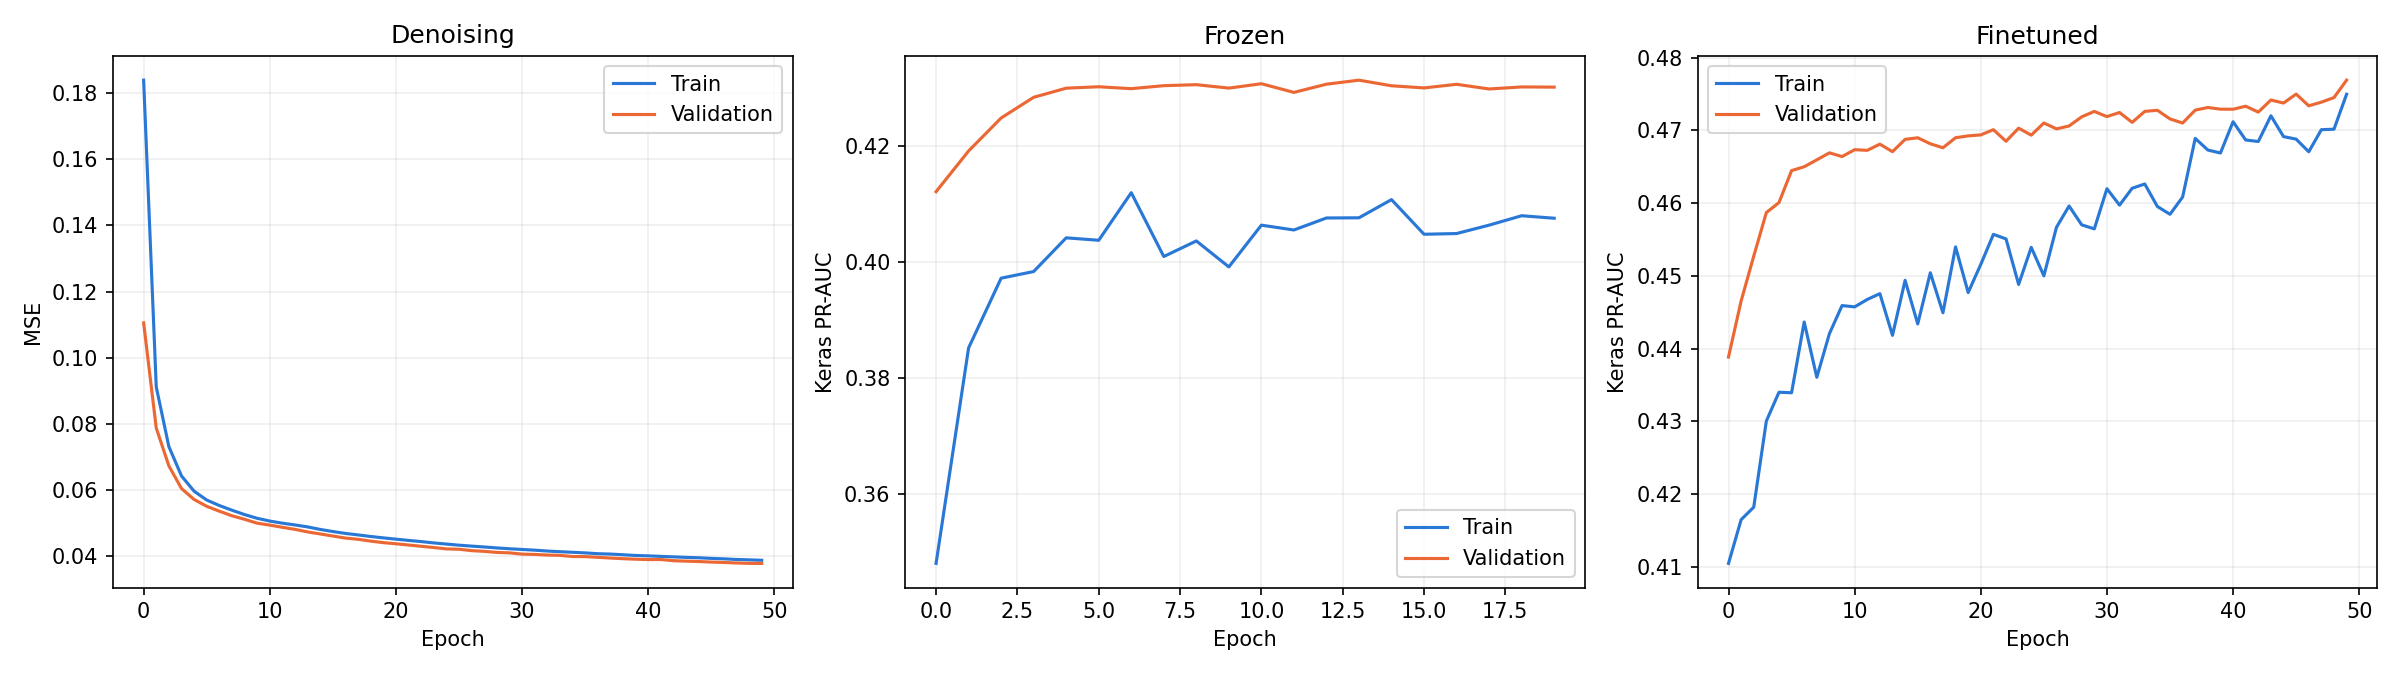

In [6]:
display(Image(filename=str(RESULTS / "learning_curves.png")))

## Final evaluation
For each stage, the decision threshold maximizes **validation F1**. The threshold is then applied to the untouched test scores. We report average precision (AP), ROC-AUC, precision, recall, F1 and accuracy. AP summarizes precision-recall performance; Keras PR-AUC is a threshold approximation used for early stopping.

,model,val_avg_precision,test_avg_precision,test_roc_auc,test_precision,test_recall,test_f1,threshold,test_accuracy
0,frozen,0.4306,0.4054,0.7779,0.4592,0.4428,0.4508,0.7150,0.8825
1,finetuned,0.4762,0.4362,0.7836,0.4340,0.5126,0.4700,0.6865,0.8741


Selected on validation: finetuned
Random AP: 0.1089


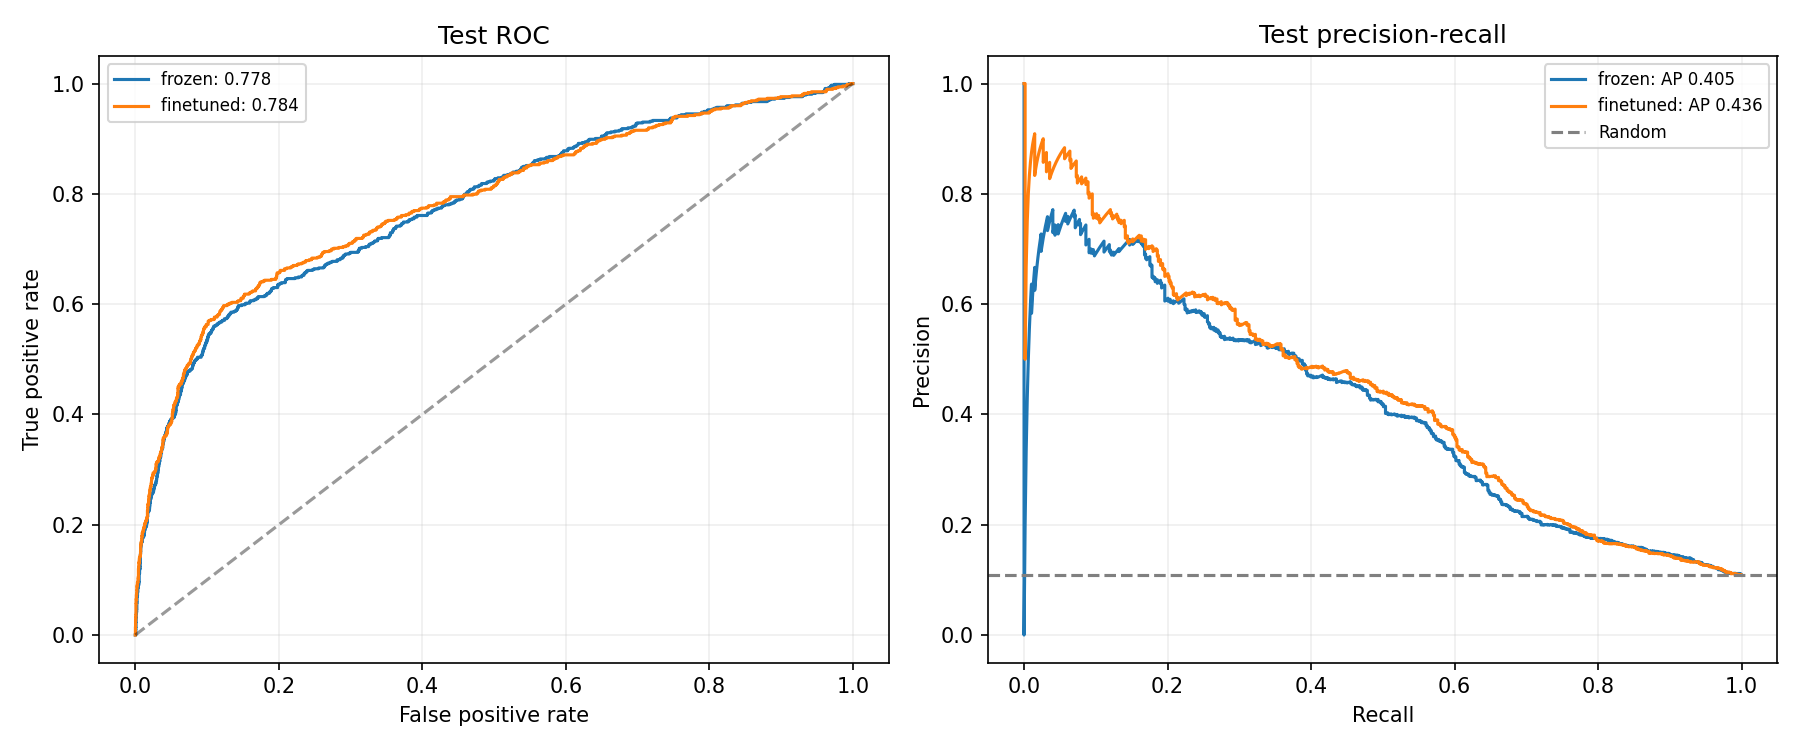

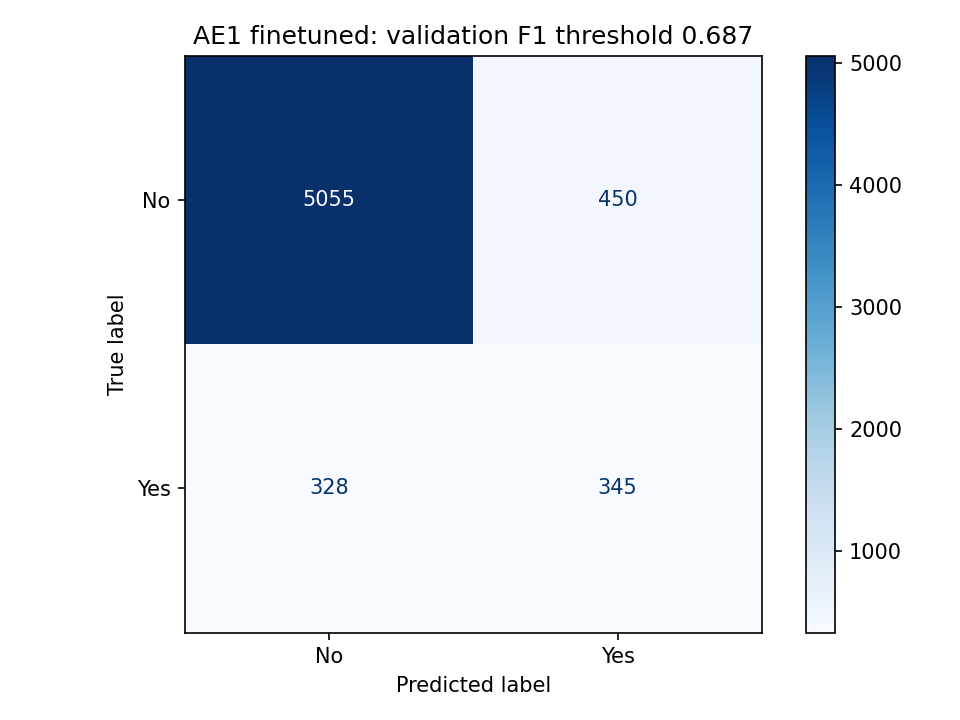

In [7]:
comparison = pd.read_csv(RESULTS / "comparison.csv")
meta = json.loads((WEIGHTS / "meta.json").read_text())
display(comparison.round(4))
print("Selected on validation:", meta["selected_stage"])
print("Random AP:", round(d["y_test"].mean(), 4))
display(Image(filename=str(RESULTS / "test_curves.png")))
display(Image(filename=str(RESULTS / "confusion_matrix.png")))

## Extra version: 2D latent space
This is a **separate, true 2-unit autoencoder**, trained on training inputs without labels. We plot only held-out test customers; labels are used only for colors. Overlap shows that a 2D unsupervised representation does not perfectly separate subscription outcomes.

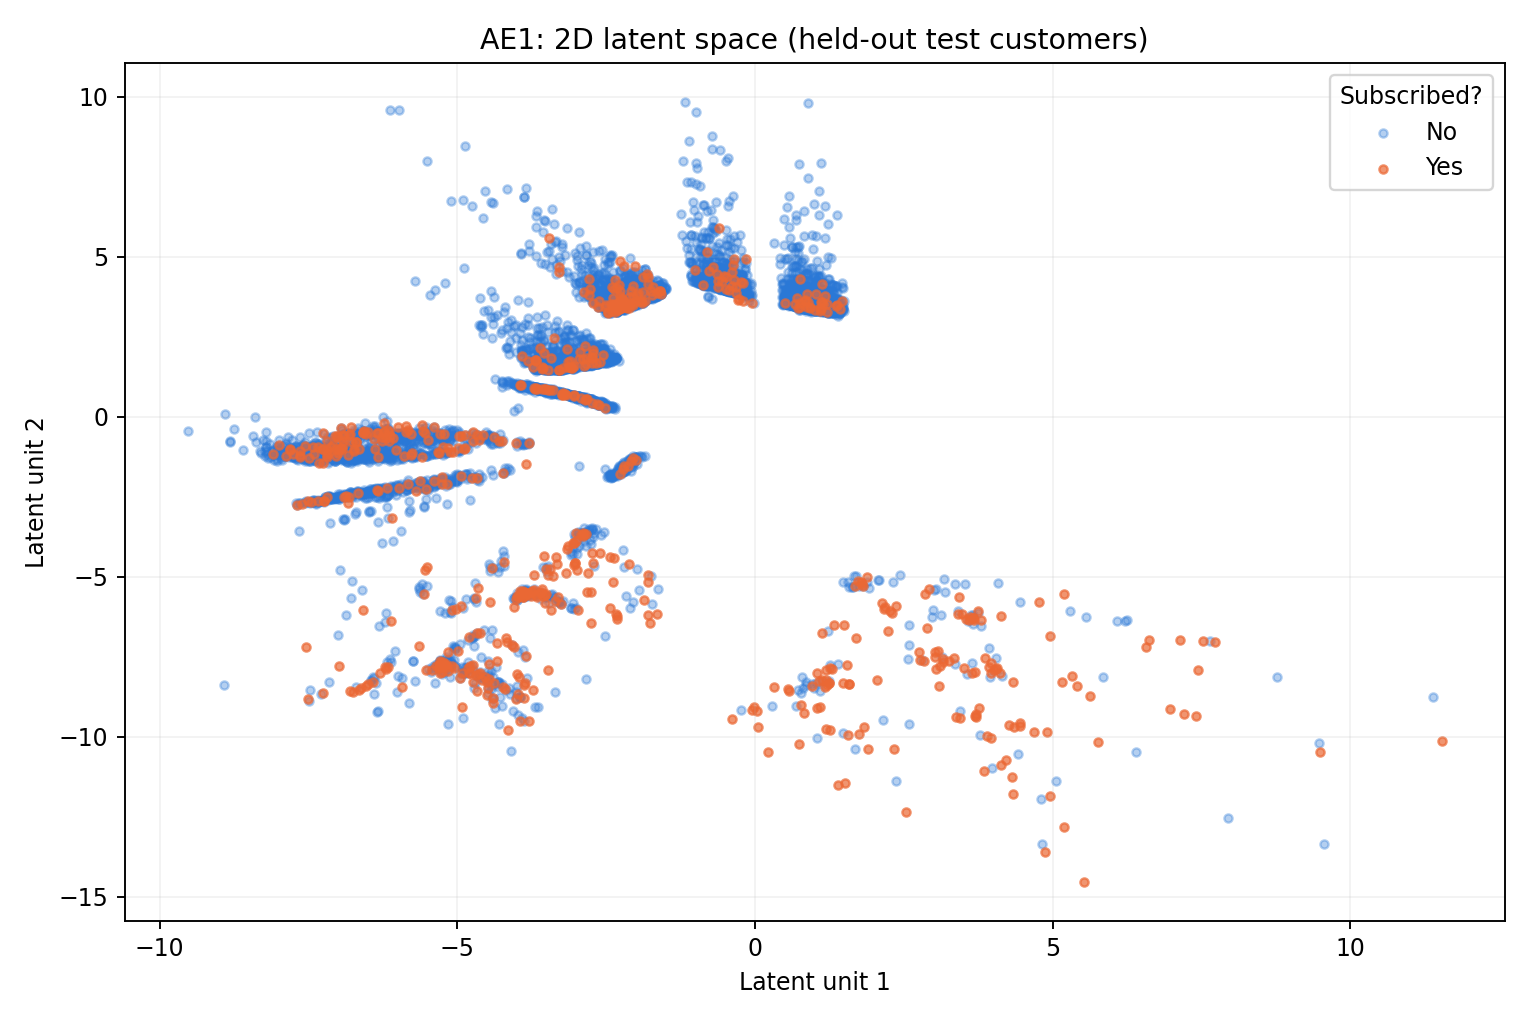

Latent shape: (6178, 2)


In [8]:
display(Image(filename=str(RESULTS / "latent_space_2d.png")))
latent = np.load(RESULTS / "latent_2d.npz")
print("Latent shape:", latent["latent"].shape)
assert latent["latent"].shape == (len(d["y_test"]), 2)
assert np.array_equal(latent["row_ids"], d["id_test"])

## Save, reload and predict
The final `.keras` model, fitted preprocessor, metadata and frozen / fine-tuned stage models are in `weights/AE1_Learned_Features/`. This uses the original raw feature columns and preserves the training transformation.

In [9]:
import joblib
model = keras.models.load_model(WEIGHTS / "model.keras", compile=False)
preprocessor = joblib.load(WEIGHTS / "preprocessor.joblib")
raw_clients = df.iloc[splits["test"][:5]].drop(columns="y")
features = preprocessor.transform(raw_clients).astype("float32")
subscription_scores = np.asarray(model(features, training=False)).ravel()
threshold = meta["metrics"]["threshold"]
display(pd.DataFrame({"subscription_score": subscription_scores,
                      "prediction": np.where(subscription_scores >= threshold, "yes", "no"),
                      "actual": np.where(d["y_test"][:5] == 1, "yes", "no")}))
assert np.isfinite(subscription_scores).all()

,subscription_score,prediction,actual
0,0.214294,no,no
1,0.191146,no,no
2,0.262387,no,no
3,0.191146,no,no
4,0.215018,no,no


## Deployment and limitations
The existing Arabic Churn Desk interface is in `deployment/churn-desk`. It supports FastAPI inference and a published browser edition with the same exported weights. The base network score is **non-subscription**; the conversation adds a separately labeled training simulation. Duration never enters AE1.

- This dataset measures subscription, not actual churn.
- Class-weighted scores are not calibrated probabilities.
- Shared group-safe random splits support team comparison but are not chronological validation.
- A compact unsupervised bottleneck can lose useful class information. Fine-tuning may help, but no improvement is assumed.
- The simulator's Arabic names and call reasons are fictional; dataset feature values are real.

Source: [UCI Bank Marketing](https://archive.ics.uci.edu/dataset/222/bank+marketing), Moro, Rita & Cortez (2014), CC BY 4.0.